---
**UNIVERSIDAD NACIONAL DE ASUNCIÓN**

**FACULTAD DE INGENIERÍA**

# **ROBÓTICA I**

TRABAJO PRÁCTICO FINAL 2026S2

## **"Robot móvil recogedor de frutas"**

---
###**Grupo [2]:** [Robot móvil recogedor de frutas]

---

**Grupo [2]:**


*   Pablo Junior Otazu Lujan
*   Gabriela Belén Orrego Arzamendia
*   Héctor Dejesús Velázquez Ojeda
*   Mathias Ramón Aguilar Delvalle

**ENTREGA [2]:** [Diseño preliminar del robot]

**Fecha:** [27/08/2026]

**Versión:** [1.0]

---
### **1. Tarea de la Estación y el Robot Cosechador**

---

#### **1.1. Descripción del Sistema**
El sistema automatizado consiste en una estación robótica móvil de navegación autónoma, equipada con un manipulador robótico articulado de 3 DOF (configuración RRR) y una herramienta con un grado de libertad rotacional adicional (cinemática total de 3+1 DOF). La estructura del manipulador se considera como una cadena cinemática formada por eslabones unidos mediante articulaciones rotacionales [[1]](https://www.mheducation.es/fundamentos-de-robotica-9788448156367-spain).

La tarea principal radica en la recolección autónoma de frutos cítricos mediante una secuencia de percepción, aproximación, manipulación y desprendimiento:
1. **Percepción:** Un sistema de visión artificial detecta la silueta del limón, la separa del resto del follaje y determina sus coordenadas específicas.
2. **Posicionamiento:** El robot móvil se desplaza hasta una zona de trabajo óptima frente al árbol.
3. **Aproximación:** El manipulador 3R calcula la cinemática inversa (IK) para posicionar la herramienta en el objetivo  [[1]](https://www.mheducation.es/fundamentos-de-robotica-9788448156367-spain).
4. **Cosecha y Depósito:** La pinza sujeta el limón, aplica una fuerza de tracción hacia el robot combinada con la rotación del efector final (+1 DOF) para desprender el tallo sin dañar la planta, y deposita el fruto en el contenedor.



#### **1.2. Objetivo Principal**

**Objetivo General:**  
 Desarrollar e integrar una plataforma robótica autónoma capaz de detectar, localizar, alcanzar y cosechar limones de forma efectiva sin dañar el fruto, coordinando de manera sincrónica la navegación móvil, la visión tridimensional, el control cinemático del brazo y los actuadores de la herramienta.



#### **1.3. Resultados Esperados (Flujo Operativo)**

Al finalizar un ciclo de trabajo, el sistema robótico debe completar autónomamente el siguiente flujo:

*  **Percepción Tridimensional:** Detectar los limones y estimar su posición espacial \(P(x,y,z)\) para utilizarla como referencia del manipulador [[2]](https://doi.org/10.3390/s140711557)
*  **Selección de Objetivo:** Identificar y seleccionar un fruto objetivo a partir de la información obtenida mediante visión artificial [[2]](https://doi.org/10.3390/s140711557)
*  **Navegación Móvil:** Posicionar la base del robot dentro de la zona de alcance del brazo.
*  **Planificación de Trayectoria:** Ejecutar el posicionamiento del manipulador 3R evitando colisiones con follaje u obstáculos.
*  **Sujeción y Cosecha:** Aplicar la presión adecuada con la pinza y desprender el fruto mediante tracción y torsión.
*  **Almacenamiento:** Retirar el fruto del árbol y depositarlo en el contenedor correspondiente.
*  **Bucle de Operación:** Repetir el procedimiento mientras se detecten frutos disponibles en la zona.

#### **1.4. Arquitectura de Componentes e Interfaces**

El sistema se compone de los siguientes subsistemas principales e interfaces de comunicación:

| Componente | Configuración / DOF | Función Principal | Tipo de Interfaz |
| :--- | :--- | :--- | :--- |
| **Robot Móvil Autónomo** | Base Móvil | Desplazamiento y posicionamiento global de la estación. | Bus CAN / ROS / Serial |
| **Manipulador Robótico** | 3 DOF (RRR) | Posicionamiento del efector final en la coordenada 3D del fruto. | Drivers de motores (PWM / Encoder) |
| **Efector Final / Herramienta** | 1 DOF Rotacional + Agarre | Sujeción por pinza y torsión del tallo del limón. | Digital I/O / Relés / Servos |
| **Visión Artificial** | Cámara RGB-D / Estéreo | Captura de imagen, segmentación y localización espacial 3D. | USB 3.0 / GigE (RTSP) |
| **Control Central** | PC Embebida | Planificación de trayectorias, máquina de estados y coordinación. | ROS 2 / Python / C++ |
| **Sensores de Propiocepción**| Encoders + Fuerza | Medición de ángulos articulares y fuerza de agarre. | Entradas Analógicas / I2C / SPI |


#### **1.5 Diagrama de bloques**

El flujo operativo del sistema sigue la siguiente secuencia funcional:

**Visión artificial** → **Localización y planificación** → **Robot móvil autónomo** → **Manipulador RRR** → **Herramienta de recolección**

A nivel de arquitectura, todos los subsistemas se comunican de forma centralizada por medio del módulo de **Control Principal** *(Fig. 1)*.

<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1oTu-XTNU0bu_rpMJ8BFlhOTeJPa6TkbW" width="700" />
  <p><b>Fig. 1.</b> Diagrama de bloques del sistema.</p>
</div>

#### **1.6 Diseño estructural**

El manipulador adopta una configuración **RRR** formada por tres articulaciones rotacionales, definidas por las siguientes dimensiones geométricas iniciales:

| Eslabón | Dimensión (Aproximada) | Descripción |
| :--- | :---: | :--- |
| **$L_1$** | **150 mm** | Altura vertical entre la base y la primera articulación |
| **$L_2$** | **300 mm** | Longitud del primer eslabón principal |
| **$L_3$** | **300 mm** | Longitud del segundo eslabón principal |

Esta configuración otorga un alcance máximo de trabajo de 650 mm, considerando la suma de los eslabones principales (**$L_2$ + $L_3$ = 600 mm**) y la longitud efectiva de la herramienta de recolección.
<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1BKez2xKbhKqwTNzVLl77g9C9bOPm1bzO" width="700" />
  <p><b>Fig. 2.</b>Diseño estructural preliminar del manipulador RRR.</p>
</div>


<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1LSZz1KtIffdb6an-XwE2cWzZ_8TZmWqp" width="700" />
  <p><b>Fig. 3.</b>Dimensiones principales del manipulador RRR.</p>
</div>

#### **1.7. Verificación Preliminar del Área de Trabajo (Workspace)**

Para evaluar si la geometría propuesta satisface la zona de cosecha requerida, se realizó una simulación geométrica del manipulador considerando sus dimensiones y límites articulares iniciales.


* ###  Parámetros Geométricos Considerados


| Parámetro | Variable | Valor |
| :--- | :---: | :---: |
| Altura de la base | $L_1$ | 150 mm |
| Primer eslabón principal | $L_2$ | 300 mm |
| Segundo eslabón principal | $L_3$ | 300 mm |
| Longitud de la herramienta | $L_h$ | 50 mm |



* ### Cálculo del Alcance Máximo ($R_{\max}$)

El alcance radial máximo del sistema se obtiene extendiendo por completo los eslabones principales y el efector final:

$$R_{\max} \approx L_2 + L_3 + L_h$$

$$R_{\max} \approx 300\,\text{mm} + 300\,\text{mm} + 50\,\text{mm} = 650\,\text{mm}$$

>  **Criterio de Validación:**  
> La zona de recolección estimada presenta un diámetro útil de $D = 300\,\text{mm}$. El valor de $R_{\max} = 650\,\text{mm}$ representa el alcance máximo teórico del manipulador. La cobertura efectiva de la zona de recolección se verifica mediante la simulación del espacio de trabajo considerando los límites articulares definidos.

<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1RHV8prA8WwEpHgPtXp211vInaLYIrQjC" width="700" />
  <p><b>Fig. 4.</b>Plano X-Z del manipulador RRR.</p>
</div>

<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1W8RPubY3XvgsxAT7YIQA-mIKk2cdJ8pc" width="700" />
  <p><b>Fig. 5.</b>Plano X-Y del manipulador RRR.</p>
</div>

##### **Proyecciones del Espacio Alcanzable**

A continuación, se presentan las proyecciones del espacio de trabajo del manipulador en los planos **X-Z** (vista lateral) y **X-Y** (vista superior), obtenidas mediante simulación numérica en Python:

## Verificación del área de trabajo – Vista X-Z

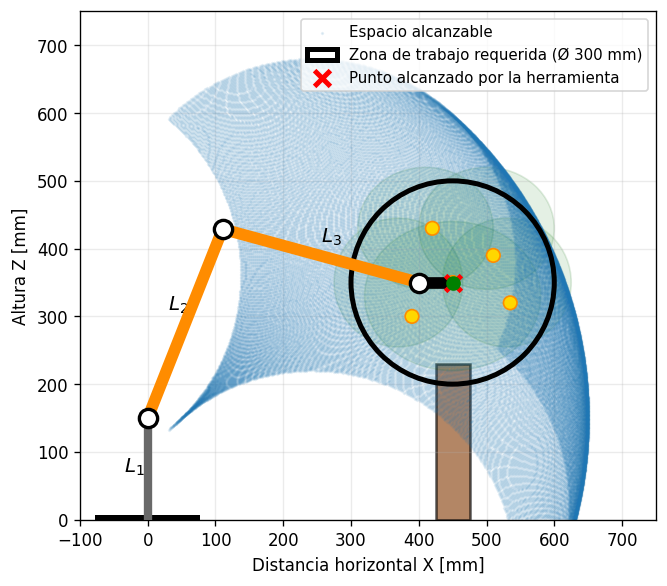

---------------------------------------------
VERIFICACIÓN DEL ÁREA DE TRABAJO
---------------------------------------------

DIMENSIONES:
L1 = 150 mm
L2 = 300 mm
L3 = 300 mm
Herramienta = 50 mm

Alcance máximo teórico = 650 mm

LÍMITES ARTICULARES:
q1 = -75° a 75° (recorrido 150°)
q2 = -25° a 135° (recorrido 160°)
q3 = -50° a 50° (recorrido 100°)

En la vista X-Z la articulación q1 no modifica la geometría mostrada.

Diámetro de la zona requerida = 300 mm
Centro de la zona = (450, 350) mm

CONFIGURACIÓN MOSTRADA:
q2 = 68.38°
q3 = -15.25°
Punto alcanzado = (450.0, 350.0) mm

Porcentaje de la zona alcanzable: 100.00 %
RESULTADO: La zona de trabajo requerida se encuentra completamente dentro del espacio alcanzable.

Nota: las líneas azules aparecen por la superposición de posiciones obtenidas al evaluar diferentes combinaciones de q2 y q3. Las zonas más marcadas indican una mayor densidad de configuraciones articulares.


In [ ]:
# @title

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, Rectangle
from IPython.display import display, Markdown


# ============================================================
# 1. DIMENSIONES DEL ROBOT
# ============================================================

L1 = 150       # Altura base -> hombro [mm]
L2 = 300       # Primer eslabón [mm]
L3 = 300       # Segundo eslabón [mm]
L_tool = 50    # Herramienta horizontal [mm]

R_max = L2 + L3 + L_tool


# ============================================================
# 2. ZONA DE TRABAJO
# ============================================================

diametro_zona = 300
radio_zona = diametro_zona / 2

# Posición preliminar de la zona de recolección
x_centro = 450
z_centro = 350


# ============================================================
# 3. LÍMITES ARTICULARES DEL ROBOT
# ============================================================

# ------------------------------------------------------------
# q1: articulación rotativa de la base
#
# Plano X-Y:
# +X hacia arriba
# +Y hacia la izquierda
#
# q1 = 0° sobre el eje +X.
# Movimiento permitido: -75° a +75°.
#
# q1 no interviene directamente en esta gráfica X-Z,
# pero se define para mantener la misma convención del robot.
# ------------------------------------------------------------

q1_min = np.deg2rad(-75)
q1_max = np.deg2rad(75)


# ------------------------------------------------------------
# q2: orientación absoluta del eslabón L2
#
# Plano X-Z:
# +X hacia la derecha
# +Z hacia arriba
#
# q2 = 0° -> L2 horizontal hacia +X
#
# Movimiento permitido:
# -25° a +135°
# Recorrido total: 160°
# ------------------------------------------------------------

q2_min = np.deg2rad(-25)
q2_max = np.deg2rad(135)


# ------------------------------------------------------------
# q3: orientación absoluta del eslabón L3
#
# También medido respecto al eje global +X.
#
# q3 = 0° -> L3 horizontal hacia +X
#
# Movimiento permitido:
# -50° a +50°
# Recorrido total: 100°
# ------------------------------------------------------------

q3_min = np.deg2rad(-50)
q3_max = np.deg2rad(50)


# ============================================================
# 4. GENERACIÓN DEL ESPACIO ALCANZABLE
# ============================================================

# Se toman 230 posiciones igualmente espaciadas
# para q2 y q3.

q2_values = np.linspace(q2_min, q2_max, 230)
q3_values = np.linspace(q3_min, q3_max, 230)

# Total:
# 230 x 230 = 52 900 configuraciones articulares.

X = []
Z = []


for q2 in q2_values:

    for q3 in q3_values:

        # ----------------------------------------------------
        # Posición del codo
        # ----------------------------------------------------

        x_elbow = (
            L2 * np.cos(q2)
        )

        z_elbow = (
            L1
            + L2 * np.sin(q2)
        )


        # ----------------------------------------------------
        # Posición de la muñeca
        #
        # q2 y q3 son ángulos ABSOLUTOS respecto a +X.
        #
        # Por eso NO se utiliza:
        # cos(q2 + q3)
        # sin(q2 + q3)
        # ----------------------------------------------------

        x_wrist = (
            L2 * np.cos(q2)
            + L3 * np.cos(q3)
        )

        z_wrist = (
            L1
            + L2 * np.sin(q2)
            + L3 * np.sin(q3)
        )


        # ----------------------------------------------------
        # Extremo de la herramienta
        #
        # Se considera que la herramienta permanece horizontal.
        # ----------------------------------------------------

        x_tool = x_wrist + L_tool
        z_tool = z_wrist


        # No considerar posiciones debajo del suelo
        if z_tool >= 0:

            X.append(x_tool)
            Z.append(z_tool)


X = np.array(X)
Z = np.array(Z)


# ============================================================
# 5. FUNCIÓN DE VERIFICACIÓN DE ALCANZABILIDAD
# ============================================================
#
# Se resuelve la geometría considerando que q2 y q3
# son orientaciones absolutas respecto al eje +X.
# ============================================================


def normalizar_angulo(angulo):

    return (
        (angulo + np.pi)
        % (2 * np.pi)
        - np.pi
    )


def punto_alcanzable(x, z):

    # --------------------------------------------------------
    # Restar longitud de la herramienta
    # y trasladar el origen hasta el hombro.
    # --------------------------------------------------------

    x_obj = x - L_tool
    z_obj = z - L1


    # Distancia al objetivo desde el hombro
    r2 = (
        x_obj**2
        + z_obj**2
    )


    # --------------------------------------------------------
    # Diferencia angular entre L2 y L3
    # mediante ley de cosenos.
    # --------------------------------------------------------

    cos_delta = (
        r2
        - L2**2
        - L3**2
    ) / (
        2 * L2 * L3
    )


    # Si está fuera del alcance geométrico
    if cos_delta < -1 or cos_delta > 1:
        return False


    cos_delta = np.clip(
        cos_delta,
        -1,
        1
    )


    delta_base = np.arccos(cos_delta)

    # Dirección del vector resultante
    phi = np.arctan2(
        z_obj,
        x_obj
    )


    # Existen dos soluciones geométricas
    for delta in [
        delta_base,
        -delta_base
    ]:

        alpha = np.arctan2(
            L2 * np.sin(delta),
            L3 + L2 * np.cos(delta)
        )


        # q3 absoluto
        q3 = normalizar_angulo(
            phi - alpha
        )


        # q2 absoluto
        q2 = normalizar_angulo(
            q3 + delta
        )


        # Verificar límites mecánicos
        if (
            q2_min <= q2 <= q2_max
            and
            q3_min <= q3 <= q3_max
        ):

            return True


    return False


# ============================================================
# 6. VERIFICACIÓN NUMÉRICA DE LA ZONA
# ============================================================

x_test = np.linspace(
    x_centro - radio_zona,
    x_centro + radio_zona,
    120
)

z_test = np.linspace(
    z_centro - radio_zona,
    z_centro + radio_zona,
    120
)


total_puntos = 0
puntos_alcanzables = 0


for x in x_test:

    for z in z_test:

        # Evaluar solamente puntos dentro
        # de la circunferencia de Ø300 mm
        if (
            (x - x_centro)**2
            + (z - z_centro)**2
            <= radio_zona**2
        ):

            total_puntos += 1

            if punto_alcanzable(x, z):

                puntos_alcanzables += 1


porcentaje = (
    100
    * puntos_alcanzables
    / total_puntos
)


# ============================================================
# 7. FUNCIÓN PARA DIBUJAR EL ÁRBOL
# ============================================================

def dibujar_arbol(ax):

    # Tronco
    tronco = Rectangle(
        (425, 0),
        50,
        230,
        facecolor='saddlebrown',
        edgecolor='black',
        linewidth=1.5,
        alpha=0.65,
        zorder=1
    )

    ax.add_patch(tronco)


    # Copa
    copa = [

        (450, 330, 260, 220),
        (370, 350, 190, 190),
        (530, 350, 190, 190),
        (410, 430, 200, 180),
        (500, 430, 200, 180)

    ]


    for x, z, ancho, alto in copa:

        ax.add_patch(

            Ellipse(

                (x, z),

                ancho,
                alto,

                facecolor='forestgreen',
                edgecolor='darkgreen',

                alpha=0.12,

                zorder=1
            )
        )


    # Limones
    limones = [

        (390, 300),
        (450, 350),
        (510, 390),
        (420, 430),
        (535, 320)

    ]


    for x, z in limones:

        ax.add_patch(

            Circle(

                (x, z),

                10,

                facecolor='gold',
                edgecolor='darkorange',

                linewidth=1,

                zorder=3
            )
        )


# ============================================================
# 8. POSTURA DE EJEMPLO DEL BRAZO
# ============================================================
#
# Esta configuración lleva aproximadamente el extremo
# de la herramienta al centro de la zona:
#
# X ≈ 450 mm
# Z ≈ 350 mm
#
# IMPORTANTE:
# q2_demo y q3_demo también son ángulos absolutos
# respecto al eje +X.
# ============================================================

q2_demo = np.deg2rad(68.38)
q3_demo = np.deg2rad(-15.25)


# Hombro
x0 = 0
z0 = L1


# ------------------------------------------------------------
# Codo
# ------------------------------------------------------------

x1 = (
    L2 * np.cos(q2_demo)
)

z1 = (
    L1
    + L2 * np.sin(q2_demo)
)


# ------------------------------------------------------------
# Muñeca
# ------------------------------------------------------------

x2 = (
    L2 * np.cos(q2_demo)
    + L3 * np.cos(q3_demo)
)

z2 = (
    L1
    + L2 * np.sin(q2_demo)
    + L3 * np.sin(q3_demo)
)


# ------------------------------------------------------------
# Herramienta
# ------------------------------------------------------------

x3 = x2 + L_tool
z3 = z2


# ============================================================
# 9. GRÁFICA
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.5, 5.5),
    dpi=120
)


# Árbol
dibujar_arbol(ax)


# ------------------------------------------------------------
# Espacio alcanzable
# ------------------------------------------------------------

ax.scatter(
    X,
    Z,
    s=1,
    alpha=0.10,
    label='Espacio alcanzable',
    zorder=2
)


# ------------------------------------------------------------
# Zona de trabajo
# ------------------------------------------------------------

zona = Circle(
    (x_centro, z_centro),
    radio_zona,
    fill=False,
    linewidth=3,
    edgecolor='black',
    label='Zona de trabajo requerida (Ø 300 mm)',
    zorder=4
)

ax.add_patch(zona)


# ------------------------------------------------------------
# Base
# ------------------------------------------------------------

ax.plot(
    [-70, 70],
    [0, 0],
    linewidth=6,
    color='black',
    zorder=6
)


# ------------------------------------------------------------
# L1
# ------------------------------------------------------------

ax.plot(
    [0, 0],
    [0, L1],
    linewidth=5,
    color='dimgray',
    zorder=6
)


# ------------------------------------------------------------
# L2
# ------------------------------------------------------------

ax.plot(
    [x0, x1],
    [z0, z1],
    linewidth=7,
    color='darkorange',
    solid_capstyle='round',
    zorder=7
)


# ------------------------------------------------------------
# L3
# ------------------------------------------------------------

ax.plot(
    [x1, x2],
    [z1, z2],
    linewidth=7,
    color='darkorange',
    solid_capstyle='round',
    zorder=7
)


# ------------------------------------------------------------
# Herramienta
# ------------------------------------------------------------

ax.plot(
    [x2, x3],
    [z2, z3],
    linewidth=7,
    color='black',
    solid_capstyle='round',
    zorder=7
)


# ============================================================
# 10. ARTICULACIONES
# ============================================================

ax.scatter(
    [x0, x1, x2],
    [z0, z1, z2],
    s=120,
    facecolor='white',
    edgecolor='black',
    linewidth=2,
    zorder=8
)


# Punta de herramienta
ax.scatter(
    x3,
    z3,
    s=90,
    marker='x',
    linewidth=3,
    color='red',
    zorder=9,
    label='Punto alcanzado por la herramienta'
)


# ============================================================
# 11. ETIQUETAS
# ============================================================

ax.text(
    -35,
    70,
    '$L_1$',
    fontsize=12,
    fontweight='bold'
)


ax.text(
    (x0 + x1) / 2 - 25,
    (z0 + z1) / 2 + 20,
    '$L_2$',
    fontsize=12,
    fontweight='bold'
)


ax.text(
    (x1 + x2) / 2,
    (z1 + z2) / 2 + 20,
    '$L_3$',
    fontsize=12,
    fontweight='bold'
)


# Centro de la zona
ax.scatter(
    x_centro,
    z_centro,
    s=60,
    color='green',
    zorder=9
)


# ============================================================
# 12. FORMATO
# ============================================================

display(
    Markdown(
        "## Verificación del área de trabajo – Vista X-Z"
    )
)


ax.set_xlabel(
    'Distancia horizontal X [mm]'
)

ax.set_ylabel(
    'Altura Z [mm]'
)


ax.set_xlim(
    -100,
    750
)

ax.set_ylim(
    0,
    750
)


ax.set_aspect(
    'equal',
    adjustable='box'
)


ax.grid(
    True,
    alpha=0.25
)


ax.legend(
    loc='upper right',
    fontsize=9
)


plt.show()


# ============================================================
# 13. RESULTADOS
# ============================================================

print('---------------------------------------------')
print('VERIFICACIÓN DEL ÁREA DE TRABAJO')
print('---------------------------------------------')

print()

print('DIMENSIONES:')
print(f'L1 = {L1} mm')
print(f'L2 = {L2} mm')
print(f'L3 = {L3} mm')
print(f'Herramienta = {L_tool} mm')

print()

print(
    f'Alcance máximo teórico = '
    f'{R_max} mm'
)

print()

print('LÍMITES ARTICULARES:')

print(
    f'q1 = '
    f'{np.rad2deg(q1_min):.0f}° '
    f'a '
    f'{np.rad2deg(q1_max):.0f}° '
    f'(recorrido 150°)'
)

print(
    f'q2 = '
    f'{np.rad2deg(q2_min):.0f}° '
    f'a '
    f'{np.rad2deg(q2_max):.0f}° '
    f'(recorrido 160°)'
)

print(
    f'q3 = '
    f'{np.rad2deg(q3_min):.0f}° '
    f'a '
    f'{np.rad2deg(q3_max):.0f}° '
    f'(recorrido 100°)'
)

print()

print(
    'En la vista X-Z la articulación q1 '
    'no modifica la geometría mostrada.'
)

print()

print(
    f'Diámetro de la zona requerida = '
    f'{diametro_zona} mm'
)

print(
    f'Centro de la zona = '
    f'({x_centro}, {z_centro}) mm'
)

print()

print('CONFIGURACIÓN MOSTRADA:')

print(
    f'q2 = '
    f'{np.rad2deg(q2_demo):.2f}°'
)

print(
    f'q3 = '
    f'{np.rad2deg(q3_demo):.2f}°'
)

print(
    f'Punto alcanzado = '
    f'({x3:.1f}, {z3:.1f}) mm'
)

print()

print(
    f'Porcentaje de la zona alcanzable: '
    f'{porcentaje:.2f} %'
)


if porcentaje >= 99.9:

    print(
        'RESULTADO: La zona de trabajo requerida '
        'se encuentra completamente dentro del '
        'espacio alcanzable.'
    )

else:

    print(
        'RESULTADO: La zona de trabajo requerida '
        'NO se encuentra completamente dentro del '
        'espacio alcanzable.'
    )


print()

print(
    'Nota: las líneas azules aparecen por la '
    'superposición de posiciones obtenidas al evaluar '
    'diferentes combinaciones de q2 y q3. Las zonas '
    'más marcadas indican una mayor densidad de '
    'configuraciones articulares.'
)

## Verificación del área de trabajo – Vista Y-X

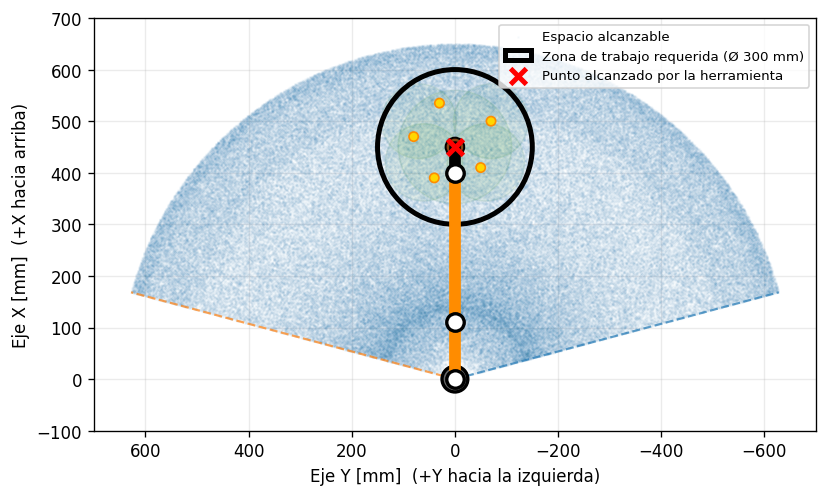

---------------------------------------------
VERIFICACIÓN DEL ÁREA DE TRABAJO – VISTA Y-X
---------------------------------------------

DIMENSIONES:
L1 = 150 mm
L2 = 300 mm
L3 = 300 mm
Herramienta = 50 mm
Alcance máximo teórico = 650 mm

LÍMITES ARTICULARES:
q1 = -75° a 75° (recorrido 150°)
q2 = -25° a 135° (recorrido 160°)
q3 = -50° a 50° (recorrido 100°)

Centro de la zona = X = 450 mm, Y = 0 mm
Diámetro de la zona = 300 mm

CONFIGURACIÓN MOSTRADA:
q1 = 0.0°
q2 = 68.38°
q3 = -15.25°

Punto mostrado: X = 450.0 mm, Y = 0.0 mm

Porcentaje de la zona alcanzable: 100.00 %
RESULTADO: La zona de trabajo requerida se encuentra completamente dentro del espacio alcanzable en la proyección Y-X.

Nota: en esta vista q1 determina la dirección del manipulador alrededor de la base, mientras que q2 y q3 determinan principalmente la distancia radial alcanzable.


In [ ]:
# @title Verificación del área de trabajo – Vista Y-X

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import display, Markdown


# ============================================================
# 1. DIMENSIONES DEL ROBOT
# ============================================================

L1 = 150       # Base -> hombro [mm]
L2 = 300       # Primer eslabón [mm]
L3 = 300       # Segundo eslabón [mm]
L_tool = 50    # Herramienta horizontal [mm]

R_max = L2 + L3 + L_tool


# ============================================================
# 2. ZONA DE TRABAJO
# ============================================================

diametro_zona = 300
radio_zona = diametro_zona / 2

# Centro de la zona visto desde arriba.
# X positivo hacia adelante/arriba
# Y positivo hacia la izquierda.
x_centro = 450
y_centro = 0


# ============================================================
# 3. LÍMITES ARTICULARES
# ============================================================

# ------------------------------------------------------------
# q1: giro de la base
# Referencia: eje +X
#
# q1 = 0°    -> +X
# q1 > 0°    -> hacia +Y (izquierda)
# q1 < 0°    -> hacia -Y (derecha)
# ------------------------------------------------------------

q1_min = np.deg2rad(-75)
q1_max = np.deg2rad(75)


# ------------------------------------------------------------
# q2: orientación absoluta de L2 respecto a +X
# en el plano X-Z
# ------------------------------------------------------------

q2_min = np.deg2rad(-25)
q2_max = np.deg2rad(135)


# ------------------------------------------------------------
# q3: orientación absoluta de L3 respecto a +X
# en el plano X-Z
# ------------------------------------------------------------

q3_min = np.deg2rad(-50)
q3_max = np.deg2rad(50)


# ============================================================
# 4. GENERACIÓN DEL ALCANCE RADIAL
# ============================================================

# Se generan 230 valores para q2 y q3.
q2_values = np.linspace(q2_min, q2_max, 230)
q3_values = np.linspace(q3_min, q3_max, 230)

Q2, Q3 = np.meshgrid(
    q2_values,
    q3_values
)


# ------------------------------------------------------------
# Alcance horizontal del brazo
#
# Como q2 y q3 están medidos respecto al eje +X:
#
# rho = L2 cos(q2) + L3 cos(q3) + L_tool
# ------------------------------------------------------------

RHO = (
    L2 * np.cos(Q2)
    + L3 * np.cos(Q3)
    + L_tool
)


# ------------------------------------------------------------
# Altura correspondiente
#
# Aunque estamos viendo el plano Y-X,
# se calcula Z para eliminar configuraciones debajo del suelo.
# ------------------------------------------------------------

Z_config = (
    L1
    + L2 * np.sin(Q2)
    + L3 * np.sin(Q3)
)


# Solo configuraciones físicamente válidas
mask = (
    (Z_config >= 0)
    & (RHO >= 0)
)

rho_valid = RHO[mask]


# ============================================================
# 5. GENERACIÓN DEL ESPACIO ALCANZABLE Y-X
# ============================================================

# Para visualizar una nube suave se toman combinaciones
# aleatorias de q1 y de los radios obtenidos anteriormente.

N = 250000

rng = np.random.default_rng(10)

indices = rng.integers(
    0,
    len(rho_valid),
    N
)

rho_sample = rho_valid[indices]

q1_sample = rng.uniform(
    q1_min,
    q1_max,
    N
)


# ------------------------------------------------------------
# Transformación polar -> cartesiana
#
# q1 se mide desde +X.
#
# X = rho cos(q1)
# Y = rho sin(q1)
# ------------------------------------------------------------

X = rho_sample * np.cos(q1_sample)
Y = rho_sample * np.sin(q1_sample)


# ============================================================
# 6. VERIFICACIÓN DE UN PUNTO EN EL PLANO Y-X
# ============================================================

rho_ordenado = np.sort(rho_valid)


def radio_alcanzable(r, tolerancia=4):

    indice = np.searchsorted(
        rho_ordenado,
        r
    )

    candidatos = []

    if indice < len(rho_ordenado):
        candidatos.append(
            abs(rho_ordenado[indice] - r)
        )

    if indice > 0:
        candidatos.append(
            abs(rho_ordenado[indice - 1] - r)
        )

    if len(candidatos) == 0:
        return False

    return min(candidatos) <= tolerancia


def punto_alcanzable_xy(x, y):

    # Distancia radial
    rho = np.sqrt(
        x**2 + y**2
    )

    # Ángulo respecto al eje +X
    q1 = np.arctan2(
        y,
        x
    )

    # Comprobar límite de q1
    if not (
        q1_min <= q1 <= q1_max
    ):
        return False

    # Comprobar si ese radio puede alcanzarse
    return radio_alcanzable(rho)


# ============================================================
# 7. VERIFICACIÓN NUMÉRICA DE LA ZONA
# ============================================================

x_test = np.linspace(
    x_centro - radio_zona,
    x_centro + radio_zona,
    140
)

y_test = np.linspace(
    y_centro - radio_zona,
    y_centro + radio_zona,
    140
)

total_puntos = 0
puntos_alcanzables = 0


for x in x_test:

    for y in y_test:

        # Solo analizar puntos dentro de la circunferencia
        if (
            (x - x_centro)**2
            + (y - y_centro)**2
            <= radio_zona**2
        ):

            total_puntos += 1

            if punto_alcanzable_xy(x, y):

                puntos_alcanzables += 1


porcentaje = (
    100
    * puntos_alcanzables
    / total_puntos
)


# ============================================================
# 8. ÁRBOL EN VISTA SUPERIOR
# ============================================================

def dibujar_arbol_superior(ax):

    # Copa principal
    copas = [
        (0, 450, 220),
        (60, 420, 150),
        (-60, 420, 150),
        (70, 500, 145),
        (-70, 500, 145)
    ]

    for y, x, diametro in copas:

        ax.add_patch(
            Circle(
                (y, x),
                diametro / 2,
                facecolor='forestgreen',
                edgecolor='darkgreen',
                alpha=0.08,
                zorder=1
            )
        )


    # Tronco visto desde arriba
    ax.add_patch(
        Circle(
            (0, 450),
            18,
            facecolor='saddlebrown',
            edgecolor='black',
            linewidth=1.2,
            zorder=3
        )
    )


    # Limones
    limones = [
        (40, 390),
        (-50, 410),
        (80, 470),
        (-70, 500),
        (30, 535)
    ]

    for y, x in limones:

        ax.add_patch(
            Circle(
                (y, x),
                9,
                facecolor='gold',
                edgecolor='darkorange',
                linewidth=1,
                zorder=4
            )
        )


# ============================================================
# 9. POSTURA DE EJEMPLO
# ============================================================

# q1 = 0°:
# el brazo apunta directamente hacia +X.

q1_demo = np.deg2rad(0)

q2_demo = np.deg2rad(68.38)
q3_demo = np.deg2rad(-15.25)


# ------------------------------------------------------------
# Proyección horizontal de L2
# ------------------------------------------------------------

rho1 = (
    L2 * np.cos(q2_demo)
)


x1 = rho1 * np.cos(q1_demo)
y1 = rho1 * np.sin(q1_demo)


# ------------------------------------------------------------
# Proyección hasta la muñeca
# ------------------------------------------------------------

rho2 = (
    L2 * np.cos(q2_demo)
    + L3 * np.cos(q3_demo)
)


x2 = rho2 * np.cos(q1_demo)
y2 = rho2 * np.sin(q1_demo)


# ------------------------------------------------------------
# Extremo de la herramienta
# ------------------------------------------------------------

rho3 = rho2 + L_tool

x3 = rho3 * np.cos(q1_demo)
y3 = rho3 * np.sin(q1_demo)


# ============================================================
# 10. GRÁFICA
# ============================================================

display(
    Markdown(
        "## Verificación del área de trabajo – Vista Y-X"
    )
)


fig, ax = plt.subplots(
    figsize=(7, 7),
    dpi=120
)


# ------------------------------------------------------------
# Árbol
# ------------------------------------------------------------

dibujar_arbol_superior(ax)


# ------------------------------------------------------------
# Espacio alcanzable
#
# IMPORTANTE:
# En el gráfico:
# horizontal = Y
# vertical   = X
# ------------------------------------------------------------

ax.scatter(
    Y,
    X,
    s=0.5,
    alpha=0.025,
    label='Espacio alcanzable',
    zorder=2
)


# ============================================================
# 11. LÍMITES ANGULARES DE q1
# ============================================================

for q_lim in [
    q1_min,
    q1_max
]:

    x_lim = (
        R_max
        * np.cos(q_lim)
    )

    y_lim = (
        R_max
        * np.sin(q_lim)
    )

    ax.plot(
        [0, y_lim],
        [0, x_lim],
        linestyle='--',
        linewidth=1.3,
        alpha=0.7,
        zorder=3
    )


# ============================================================
# 12. ZONA DE TRABAJO
# ============================================================

zona = Circle(
    (y_centro, x_centro),
    radio_zona,
    fill=False,
    linewidth=3,
    edgecolor='black',
    label='Zona de trabajo requerida (Ø 300 mm)',
    zorder=5
)

ax.add_patch(zona)


# ============================================================
# 13. BASE DEL ROBOT
# ============================================================

base = Circle(
    (0, 0),
    25,
    facecolor='dimgray',
    edgecolor='black',
    linewidth=2,
    zorder=7
)

ax.add_patch(base)


# ============================================================
# 14. BRAZO PROYECTADO
# ============================================================

# L2
ax.plot(
    [0, y1],
    [0, x1],
    linewidth=7,
    color='darkorange',
    solid_capstyle='round',
    zorder=8
)


# L3
ax.plot(
    [y1, y2],
    [x1, x2],
    linewidth=7,
    color='darkorange',
    solid_capstyle='round',
    zorder=8
)


# Herramienta
ax.plot(
    [y2, y3],
    [x2, x3],
    linewidth=7,
    color='black',
    solid_capstyle='round',
    zorder=8
)


# ============================================================
# 15. ARTICULACIONES
# ============================================================

ax.scatter(
    [0, y1, y2],
    [0, x1, x2],
    s=110,
    facecolor='white',
    edgecolor='black',
    linewidth=2,
    zorder=9
)


# Punta
ax.scatter(
    y3,
    x3,
    s=90,
    marker='x',
    linewidth=3,
    color='red',
    label='Punto alcanzado por la herramienta',
    zorder=10
)


# ============================================================
# 16. FORMATO
# ============================================================

ax.set_xlabel(
    'Eje Y [mm]  (+Y hacia la izquierda)'
)

ax.set_ylabel(
    'Eje X [mm]  (+X hacia arriba)'
)


ax.set_xlim(
    -700,
    700
)

ax.set_ylim(
    -100,
    700
)


# Invertimos el eje horizontal para que +Y
# aparezca visualmente hacia la izquierda.
ax.invert_xaxis()


ax.set_aspect(
    'equal',
    adjustable='box'
)


ax.grid(
    True,
    alpha=0.25
)


ax.legend(
    loc='upper right',
    fontsize=8
)


plt.tight_layout()
plt.show()


# ============================================================
# 17. RESULTADOS
# ============================================================

print('---------------------------------------------')
print('VERIFICACIÓN DEL ÁREA DE TRABAJO – VISTA Y-X')
print('---------------------------------------------')

print()

print('DIMENSIONES:')
print(f'L1 = {L1} mm')
print(f'L2 = {L2} mm')
print(f'L3 = {L3} mm')
print(f'Herramienta = {L_tool} mm')
print(f'Alcance máximo teórico = {R_max} mm')

print()

print('LÍMITES ARTICULARES:')

print(
    f'q1 = '
    f'{np.rad2deg(q1_min):.0f}° '
    f'a '
    f'{np.rad2deg(q1_max):.0f}° '
    f'(recorrido 150°)'
)

print(
    f'q2 = '
    f'{np.rad2deg(q2_min):.0f}° '
    f'a '
    f'{np.rad2deg(q2_max):.0f}° '
    f'(recorrido 160°)'
)

print(
    f'q3 = '
    f'{np.rad2deg(q3_min):.0f}° '
    f'a '
    f'{np.rad2deg(q3_max):.0f}° '
    f'(recorrido 100°)'
)

print()

print(
    f'Centro de la zona = '
    f'X = {x_centro} mm, '
    f'Y = {y_centro} mm'
)

print(
    f'Diámetro de la zona = '
    f'{diametro_zona} mm'
)

print()

print('CONFIGURACIÓN MOSTRADA:')

print(
    f'q1 = '
    f'{np.rad2deg(q1_demo):.1f}°'
)

print(
    f'q2 = '
    f'{np.rad2deg(q2_demo):.2f}°'
)

print(
    f'q3 = '
    f'{np.rad2deg(q3_demo):.2f}°'
)

print()

print(
    f'Punto mostrado: '
    f'X = {x3:.1f} mm, '
    f'Y = {y3:.1f} mm'
)

print()

print(
    f'Porcentaje de la zona alcanzable: '
    f'{porcentaje:.2f} %'
)


if porcentaje >= 99.9:

    print(
        'RESULTADO: La zona de trabajo requerida '
        'se encuentra completamente dentro del '
        'espacio alcanzable en la proyección Y-X.'
    )

else:

    print(
        'RESULTADO: La zona de trabajo requerida '
        'NO se encuentra completamente dentro del '
        'espacio alcanzable en la proyección Y-X.'
    )


print()

print(
    'Nota: en esta vista q1 determina la dirección '
    'del manipulador alrededor de la base, mientras '
    'que q2 y q3 determinan principalmente la '
    'distancia radial alcanzable.'
)

In [ ]:
# @title
import numpy as np
import plotly.graph_objects as go

# ============================================================
# 1. PARÁMETROS DEL ROBOT (mm)
# ============================================================
L1 = 150.0
L2 = 300.0
L3 = 300.0
Lt = 50.0
print(f"Alcance máximo teórico (L2+L3+Lt) = {L2+L3+Lt} mm")

# ============================================================
# 2. LÍMITES ARTICULARES (grados)
# ============================================================
q1_min, q1_max = -75, 75      # base, plano X-Y (actualizado)
q2_min, q2_max = -25, 135     # eslabón 2, plano X-Z
q3_min, q3_max = -50, 50      # eslabón 3, plano X-Z

n1, n2, n3 = 45, 45, 45

q1_range = np.radians(np.linspace(q1_min, q1_max, n1))
q2_range = np.radians(np.linspace(q2_min, q2_max, n2))
q3_range = np.radians(np.linspace(q3_min, q3_max, n3))

Q1, Q2, Q3 = np.meshgrid(q1_range, q2_range, q3_range, indexing='ij')

# ============================================================
# 3. CINEMÁTICA DIRECTA -> NUBE DE PUNTOS DEL WORKSPACE
# ============================================================
r = (
    L2 * np.cos(Q2)
    + L3 * np.cos(Q3)
    + Lt
)

z = (
    L1
    + L2 * np.sin(Q2)
    + L3 * np.sin(Q3)
)

X = (r * np.cos(Q1)).flatten()
Y = (r * np.sin(Q1)).flatten()
Z = z.flatten()

Q1f = Q1.flatten()
Q2f = Q2.flatten()
Q3f = Q3.flatten()
# ============================================================
# 3b. FILTRAR PUNTOS CON Z < 0 (no tienen sentido físico)
# ============================================================
mask = Z >= 0

X = X[mask]
Y = Y[mask]
Z = Z[mask]
Q1f = Q1f[mask]
Q2f = Q2f[mask]
Q3f = Q3f[mask]

print(f"Puntos descartados por Z<0: {np.sum(~mask)} de {mask.size}")
# ============================================================
# 4. ZONA DE TRABAJO REQUERIDA (ESFERA)
# ============================================================
diametro_zona = 300
radio_zona = diametro_zona / 2

r_centro = 450
q1_centro = np.deg2rad(0)     # ajustado al nuevo rango centrado en X (-75° a 75°)
z_centro = 350

x_centro = r_centro * np.cos(q1_centro)
y_centro = r_centro * np.sin(q1_centro)

u = np.linspace(0, 2 * np.pi, 35)
v = np.linspace(0, np.pi, 20)

Xs = x_centro + radio_zona * np.outer(np.cos(u), np.sin(v))
Ys = y_centro + radio_zona * np.outer(np.sin(u), np.sin(v))
Zs = z_centro + radio_zona * np.outer(np.ones(np.size(u)), np.cos(v))

# ============================================================
# 5. VERIFICACIÓN DE ALCANCE
# ============================================================
dist_base_centro = np.sqrt(x_centro**2 + y_centro**2 + z_centro**2)

dists = np.sqrt((X - x_centro)**2 + (Y - y_centro)**2 + (Z - z_centro)**2)
idx_min = np.argmin(dists)
dist_min = dists[idx_min]

q1_sel, q2_sel, q3_sel = Q1f[idx_min], Q2f[idx_min], Q3f[idx_min]

print("=" * 60)
print("VERIFICACIÓN DE ALCANCE")
print("=" * 60)
print(f"Distancia base -> centro de esfera : {dist_base_centro:.1f} mm")
print(f"Alcance máx. teórico del brazo     : {L2+L3+Lt:.1f} mm")
print(f"Punto más cercano del workspace al centro de la esfera:")
print(f"   distancia = {dist_min:.1f} mm  (radio de la zona = {radio_zona} mm)")
if dist_min <= radio_zona:
    print("-> El robot SÍ puede alcanzar el interior de la zona requerida.")
else:
    print("-> El robot NO alcanza el interior de la zona con la config. actual.")

# ============================================================
# 6. ESQUELETO DEL BRAZO EN LA CONFIGURACIÓN SELECCIONADA
# ============================================================
P0 = np.array([0, 0, 0])
P1 = np.array([0, 0, L1])

r2 = L2 * np.cos(q2_sel)
z2 = L1 + L2 * np.sin(q2_sel)
P2 = np.array([r2 * np.cos(q1_sel), r2 * np.sin(q1_sel), z2])

r3 = L2 * np.cos(q2_sel) + L3 * np.cos(q3_sel)
z3 = L1 + L2 * np.sin(q2_sel) + L3 * np.sin(q3_sel)
P3 = np.array([r3 * np.cos(q1_sel), r3 * np.sin(q1_sel), z3])

r4 = (
    L2 * np.cos(q2_sel)
    + L3 * np.cos(q3_sel)
    + Lt
)

z4 = (
    L1
    + L2 * np.sin(q2_sel)
    + L3 * np.sin(q3_sel)
)
P4 = np.array([r4 * np.cos(q1_sel), r4 * np.sin(q1_sel), z4])

puntos = np.array([P0, P1, P2, P3, P4])

def dist(a, b):
    return np.linalg.norm(np.array(a) - np.array(b))

print("\nLongitudes verificadas del esqueleto dibujado:")
print(f"  L1 (base->q2)     = {dist(P0,P1):.1f} mm  (nominal {L1})")
print(f"  L2 (q2->codo)     = {dist(P1,P2):.1f} mm  (nominal {L2})")
print(f"  L3 (codo->fin L3) = {dist(P2,P3):.1f} mm  (nominal {L3})")
print(f"  Lt (herramienta)  = {dist(P3,P4):.1f} mm  (nominal {Lt})")

# ============================================================
# 7. GRÁFICO 3D
# ============================================================
fig = go.Figure()

fig.add_trace(go.Scatter3d(
    x=X, y=Y, z=Z,
    mode='markers',
    marker=dict(size=1.5, color=Z, colorscale='Viridis', opacity=0.25,
                colorbar=dict(title="Z (mm)")),
    name="Workspace"
))

fig.add_trace(go.Surface(
    x=Xs, y=Ys, z=Zs,
    opacity=0.5,
    colorscale=[[0, 'red'], [1, 'red']],
    showscale=False,
    name="Zona requerida"
))

fig.add_trace(go.Scatter3d(
    x=puntos[:, 0], y=puntos[:, 1], z=puntos[:, 2],
    mode='lines+markers+text',
    line=dict(color='black', width=8),
    marker=dict(size=5, color=['gray', 'blue', 'blue', 'orange', 'green']),
    text=["Base", "q2", "Codo", "fin L3", "Efector"],
    textposition="top center",
    name="Brazo (pose seleccionada)"
))

fig.update_layout(
    title="Espacio de trabajo + Zona requerida + Esqueleto del brazo",
    scene=dict(
        xaxis_title="X (mm)",
        yaxis_title="Y (mm)",
        zaxis_title="Z (mm)",
        aspectmode='data'
    ),
    width=950,
    height=850,
    legend=dict(x=0.02, y=0.98)
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.



---
### **2. Herramienta (Efector Final)**
---
#### **2.1 Descripción de la herramienta**

Para la recolección se seleccionó una herramienta basada en sujeción mediante pinza y rotación del limón. La pinza permite mantener el limón sujeto durante la operación, mientras que el movimiento rotacional se utiliza para facilitar su desprendimiento.

Existen diferentes mecanismos empleados en robots de cosecha, entre ellos herramientas de agarre para cítricos y mecanismos que combinan sujeción y torsión. En uno de los casos revisados se utiliza un efector de dos dedos que realiza el agarre y posteriormente aplica una rotación para separar la fruta[[3]](https://doi.org/10.3390/agriculture14081310).
#### **2.2 Principio de funcionamiento**

El ciclo operacional para el desprendimiento del limón sigue una secuencia cinemática en cuatro fases continuas:


<p align="center" style="font-size: 16px;">
  <b>Sujeción</b> &rarr; <b>Tensión Axial</b> &rarr; <b>Torsión</b> &rarr; <b>Retracción</b>
</p>

1. **Sujeción:** Cierre controlado de las mordazas sobre el fruto hasta alcanzar la fuerza de sujeción requerida sin comprometer la integridad de la corteza.
2. **Tensión axial:** Generación de una ligera fuerza de tracción lineal para tensar el tallo y estabilizar la postura de trabajo.
3. **Torsión:** Activación de la articulación rotativa para girar el fruto sobre su eje longitudinal, favoreciendo el desprendimiento del tallo mediante la combinación de tracción y torsión.
4. **Retracción:** Trayectoria de alejamiento del manipulador para retirar el fruto desprendido fuera de la copa del árbol.

#### **2.3 Bosquejo del efector final**

El diseño propuesto separa las funciones de sujeción y desprendimiento. Primero se realiza el cierre de la pinza sobre el limón mediante un mecanismo de aprehensión (mordazas accionadas por un mecanismo articulado) y posteriormente se aplica el movimiento rotacional, manteniendo el agarre durante la extracción y el traslado. Para ambos movimientos rotacionales se utilizará motores servo de alto torque.


<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1s1JjJyCEZStWSfZLVwBiuzotIrNJDo1v" width="500" />
  <p><b>Fig. 6.</b> Esquema 2D y mecanismo de agarre de la pinza.</p>
</div>


#### **2.4 Diseño preliminar de la herramienta**

A partir del concepto planteado en el bosquejo anterior se desarrolló un diseño
CAD preliminar del efector final. El conjunto integra el mecanismo de apertura y
cierre de las mordazas con el sistema de unión al actuador encargado de producir
la rotación de la herramienta.

El diseño permite mantener el fruto sujeto durante las etapas de tracción y
torsión, procurando además mantener una estructura compacta para reducir la masa
ubicada en el extremo del manipulador.


<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1oY4ByWm0oYS7uPQxp1sQUAR5QsVV044d" width="500" />
  <p><b>Fig. 7.</b> Vista isométrica del efector final.</p>
</div>






---

#### **3. Funcionamiento lógico**
---

El funcionamiento de la estación se organiza mediante la integración de las
etapas de percepción, localización, planificación, manipulación y
desprendimiento de la fruta, siguiendo una arquitectura funcional común en
sistemas robóticos de cosecha [[4]](https://doi.org/10.3390/agronomy16121127).


<div align="center">
  <img src="https://lh3.googleusercontent.com/d/1_lWtnjWjy4VjDFwzFNbpHhnes3mHvF4c" width="900" />
  <p><b>Fig. 8.</b> Diagrama de flujo de los componentes lógicos.</p>
</div>


### **3.1 Submódulos de la estación**

| Submódulo | Función Principal |
| :--- | :--- |
| **Visión artificial** | Procesamiento de imágenes en tiempo real para la detección, y localización 3D del fruto. |
| **Localización y planificación** | Selección estratégica del fruto objetivo y cálculo computacional de las posibles trayectorias. |
| **Navegación autónoma** | Control cinemático de la plataforma móvil para el desplazamiento y posicionamiento frente a la zona de cosecha. |
| **Manipulador RRR** | Posicionamiento espacial de precisión del efector final en el espacio de trabajo (3 DOF). |
| **Efector final (Herramienta)** | Aprehensión, tensión axial y aplicación de torsión sobre el tallo del limón. |
| **Clasificación y almacenamiento** | Categorización, transporte y depósito seguro del fruto en el contenedor final. |


#### **3.2 Secuencia general de funcionamiento**

La secuencia lógica general del sistema está representada en el siguiente gráfico:

<div align="center">
  <img src="https://drive.google.com/uc?export=view&id=1EE0OQA5cpGw_CWdoOs-Mkr69wok5j7lW" width="400" />
  <p><b>Fig. 9.</b> Diagrama de secuencia lógica general de la cosecha.</p>
</div>


---


---

#### **4. Referencias**

[1] A. Barrientos, L. F. Peñín, C. Balaguer y R. Aracil, *Fundamentos de Robótica*, 2.ª ed., Madrid: McGraw-Hill/Interamericana de España, 2007.

[2] D. Font, T. Pallejà, M. Tresanchez, D. Runcan, J. Moreno, D. Martínez, M. Teixidó y J. Palacín,  
“A proposal for automatic fruit harvesting by combining a low cost stereovision camera and a robotic arm,”  
*Sensors*, vol. 14, no. 7, pp. 11557–11579, 2014.  
DOI: [10.3390/s140711557](https://doi.org/10.3390/s140711557)

[3] C. Han, J. Lv, C. Dong, J. Li, Y. Luo, W. Wu y M. A. Abdeen,  
“Classification, advanced technologies, and typical applications of end-effector for fruit and vegetable picking robots,”  
*Agriculture*, vol. 14, no. 8, art. 1310, 2024.  
DOI: [10.3390/agriculture14081310](https://doi.org/10.3390/agriculture14081310)

[4] M. Ghonimy y N. F. Abdel-Baky,  
“Robotic fruit harvesting systems: Integration of perception, manipulation, and detachment for autonomous harvesting,”  
*Agronomy*, vol. 16, no. 12, art. 1127, 2026.  
DOI: [10.3390/agronomy16121127](https://doi.org/10.3390/agronomy16121127)




---
### **5. Carpeta del proyecto grupo 2**
En el link se encuentra la carpeta del proyecto.
[TPF R1 Grupo 2](https://drive.google.com/drive/folders/1d2jONLnkB8FMkP2iqF4ia4UeQ2jRpffz)